## ABMIL Model Development

### Importing and loading data

In [ ]:
from pathlib import Path
import h5py
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.nn import functional as F

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FEAT = ROOT / "features/lunit_vits16"

manifest = pd.read_csv(ROOT / "data/manifest.csv", dtype={"patient_id": str})
# first patient from yale cohort
row = manifest[manifest.cohort == "yale"].iloc[0]

with h5py.File(FEAT / "yale" / f"{row.patient_id}.h5") as f:
    # stored as fp16; models expect fp32
    feats = f["features"][:].astype(np.float32)  

x = torch.from_numpy(feats)          

## Developing the model

In [ ]:
class ABMIL(nn.Module):
    def __init__(self, in_dim=384, hidden_dim=128, attn_dim=64, dropout=0.25):
        super().__init__()
        # projection layer to reduce embedding dimension from 384 to 128
        self.proj_layer = nn.Sequential(
            nn.Linear(in_dim, hidden_dim), #(384, 128)
            nn.ReLU(),
            nn.Dropout(dropout)
        )
        self.attn_branch_u = nn.Sequential(
            nn.Linear(hidden_dim, attn_dim),
            nn.Sigmoid()
        )
        self.attn_branch_v = nn.Sequential(
            nn.Linear(hidden_dim, attn_dim),
            nn.Tanh()
        )
        self.attn_w = nn.Linear(attn_dim, 1)
        self.linear_head = nn.Linear(hidden_dim, 1)
        
    def forward(self, X):
        h = self.proj_layer(X)
        sig_side = self.attn_branch_u(h)
        tan_side = self.attn_branch_v(h)
        a_scores = self.attn_w(sig_side * tan_side)
        a = F.softmax(a_scores, dim=0)
        # slide/patient embedding
        z = torch.sum(a * h, dim=0)
        logits = self.linear_head(z)
        return logits, a

In [ ]:
# Functions to track dimensions and tensor stats during the forward pass
def describe(name, t):
    print(f"{name:8s} shape={tuple(t.shape)}  min={t.min():.3f}  max={t.max():.3f}  "
          f"mean={t.mean():.3f}  zeros={(t == 0).float().mean():.1%}")
    
def trace(model, x):
    """Print the output of each top-level layer as the real forward pass runs."""
    handles = [m.register_forward_hook(lambda mod, inp, out, name=name: describe(name, out))
               for name, m in model.named_children()]
    try:
        logit, a = model(x)
    finally:
        for h in handles:
            h.remove()                      
    describe("attn weights", a)
    print("sum of weights:", a.sum().item())
    return logit, a

In [ ]:
# Note: the attention weights are only printed after the forward pass - why they are out of order
trace(ABMIL(), x)

proj_layer shape=(1920, 128)  min=0.000  max=6.088  mean=0.554  zeros=60.9%
attn_branch_u shape=(1920, 64)  min=0.115  max=0.918  mean=0.503  zeros=0.0%
attn_branch_v shape=(1920, 64)  min=-0.993  max=0.989  mean=0.031  zeros=0.0%
attn_w   shape=(1920, 1)  min=-0.059  max=0.567  mean=0.235  zeros=0.0%
linear_head shape=(1,)  min=-0.319  max=-0.319  mean=-0.319  zeros=0.0%
attn weights shape=(1920, 1)  min=0.000  max=0.001  mean=0.001  zeros=0.0%
sum of weights: 0.9999998807907104


(tensor([-0.3186], grad_fn=<UnsafeViewBackward0>),
 tensor([[0.0006],
         [0.0006],
         [0.0005],
         ...,
         [0.0005],
         [0.0006],
         [0.0007]], grad_fn=<SoftmaxBackward0>))

In [ ]:
# Total model parameters
model = ABMIL()
print(f"Total model parameters: {sum(p.numel() for p in model.parameters())}")

Total model parameters: 65986


All parameters in the model come from the linear FC layers:
- one in the projection layer (384 -> 128)
- two in the gated attention pooling layer (both 128 -> 64)
- one in the classifier head (128 -> 1)

In [ ]:
# In eval mode, model should return exactly the same logits -> deterministic
# In training mode, logits should vary slightly since dropout will zero random set of values
model.eval()
l1, _ = model(x); l2, _ = model(x)

print(f"Eval mode: {l1.item(), l2.item()}")
model.train()
l3, _ = model(x); l4, _ = model(x)
print(f"Training mode: {l3.item(), l4.item()}")  

Eval mode: (-0.5613055229187012, -0.5613055229187012)
Training mode: (-0.5599648952484131, -0.5560845732688904)


In [ ]:
# Ensuring dev ABMIL model hasn't drifted from final ABMIL model
from her2_pcr_pathology_fm.models import ABMIL as ABMILFinal

dev, final = ABMIL(), ABMILFinal()
final.load_state_dict(dev.state_dict())
dev.eval(); final.eval()
print(torch.allclose(dev(x)[0], final(x)[0]))

True


### Training Loop

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from torch.nn import BCEWithLogitsLoss
from her2_pcr_pathology_fm.evaluate import load_bags

# hyperparameters
batch_size = 32  # how many independent sequences will we process in parallel?
block_size = 8  # what is the maximum context length for predictions?
max_iters = 5000
eval_interval = 300
# Decreased learning rate from 1e-2 to 1e-3 since self-attention cannot tolerate high learning rates
learning_rate = 1e-4
device = "cuda" if torch.cuda.is_available() else "cpu"
eval_iters = 200
n_embd = 32
n_epochs = 50

In [ ]:
# Loading tile bags
ids, y, bags = load_bags(cohort="yale", encoder="lunit_vits16", data_root=ROOT / "data", feat_root=ROOT / "features")
# Splitting bags into training and validation set
train_bags, val_bags, train_y, val_y, train_ids, val_ids = train_test_split(
    bags, y, ids, test_size=0.3, stratify=y, random_state=1337)

In [ ]:
@torch.no_grad()
def evaluate(model, bags, labels, criterion, device):
    model.eval()
    losses, probs = [], []
    for bag, label in zip(bags, labels):
        bag_t = torch.from_numpy(bag).to(device)
        label_t = torch.tensor([float(label)], device=device)
        logit, _ = model(bag_t)
        loss = criterion(logit, label_t).item()
        losses.append(loss)
        prob = torch.sigmoid(logit).item()  
        probs.append(prob)
    mean_loss = np.mean(losses)
    auc = roc_auc_score(labels, probs)
    return mean_loss, auc, probs

#### Check 1: Loss and Activations at Initialization

In [ ]:
# Setup
seed = 1337
torch.manual_seed(seed)

model = ABMIL()
model = model.to(device)

optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=0.01)

n_pos = int(train_y.sum())
n_neg = len(train_y) - n_pos
criterion = BCEWithLogitsLoss(pos_weight=torch.tensor([n_neg/n_pos], device=device))

In [ ]:
# Loss at initialization
mean_train_loss, train_auc, _ = evaluate(model, train_bags, train_y, criterion, device)
print(f"Mean training loss at initialization: {mean_train_loss}")

Mean training loss at initialization: 0.8120418776900081


Untrained model has probabilities close to 0.5 for each class -> binary cross entropy: ln(2) = 0.69
- pos_weight in criterion shifts it slightly to account for class imbalance

In [ ]:
# Checking activations at initialization
model.eval()
tanh_sat, sig_sat, dead = [], [], []

with torch.no_grad():
    for bag in train_bags[:10]:
        bag_t = torch.from_numpy(bag).to(device)
        h = model.proj_layer(bag_t)
        # tanh branch
        t = model.attn_branch_v(h)
        # sigmoid branch
        s = model.attn_branch_u(h)
        
        tanh_sat.append((t.abs() > 0.97).float().mean().item())
        sig_sat.append(((s < 0.03) | (s > 0.97)).float().mean().item())
        dead.append((h == 0).all(dim=0).float().mean().item())

print(f"tanh saturated (|x| > 0.97):        mean {np.mean(tanh_sat):.1%}, max {np.max(tanh_sat):.1%}")
print(f"sigmoid saturated (<0.03 or >0.97): mean {np.mean(sig_sat):.1%}, max {np.max(sig_sat):.1%}")
print(f"dead ReLU units (0 for every tile): mean {np.mean(dead):.1%}, max {np.max(dead):.1%}")        

tanh saturated (|x| > 0.97):        mean 0.0%, max 0.0%
sigmoid saturated (<0.03 or >0.97): mean 0.0%, max 0.0%
dead ReLU units (0 for every tile): mean 2.0%, max 3.9%


Checking that gradients can flow back through every layer by checking the following:
- tanh and sigmoid activations are not saturated near extremes
- no ReLU units are dead (zero for every tile)

#### Check 2: Checking if model can learn - overfitting a few examples

In [ ]:
# First 4 bags of each label
idx = np.concatenate([np.where(train_y == 1)[0][:4], np.where(train_y == 0)[0][:4]])
tiny_bags = [train_bags[i] for i in idx]
tiny_y = train_y[idx]

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

def plot_history(history, panels, log_panels=(), title=None):
    """panels: list of lists of history keys, one inner list per subplot.
       log_panels: indices of panels to draw with a log y-axis."""
    hist = pd.DataFrame(history)
    fig, axes = plt.subplots(1, len(panels), figsize=(5 * len(panels), 3.5), squeeze=False)
    for j, (ax, keys) in enumerate(zip(axes.flat, panels)):
        for k in keys:
            ax.plot(hist["epoch"], hist[k], label=k)
        ax.set_xlabel("epoch")
        ax.grid(alpha=0.3)
        ax.legend()
        if j in log_panels:
            ax.set_yscale("log")
    if title:
        fig.suptitle(title)
    fig.tight_layout()
    plt.show()

In [ ]:
seed = 1337
torch.manual_seed(seed)
rng = np.random.default_rng(seed)

model = ABMIL(dropout=0)
model = model.to(device)

optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=0.01)

criterion = BCEWithLogitsLoss()

history = []
# for each epoch, shuffle order of training bags differently
for epoch in range(n_epochs):
    model.train()
    order = rng.permutation(len(tiny_bags))
    for i in order:
        bag, label = tiny_bags[i], tiny_y[i]
        # Convert bags, labels to tensors
        bag_t = torch.from_numpy(bag).to(device)
        label_t = torch.tensor([float(label)], device=device)
        
        # forward pass
        logit, attn = model(bag_t)
        # calculate loss
        loss = criterion(logit, label_t)
        
        # backward pass
        # clearing gradients from previous step
        optimizer.zero_grad(set_to_none=True)
        # calculate gradients for all params
        loss.backward()
        # use gradients to update parameters to minimize loss
        optimizer.step()
    
    # Evaluate at the end of each epoch
    mean_train_loss, train_auc, _ = evaluate(model, tiny_bags, tiny_y, criterion, device)
    history.append({"epoch": epoch, "mean_train_loss": mean_train_loss, "train_auc": train_auc})

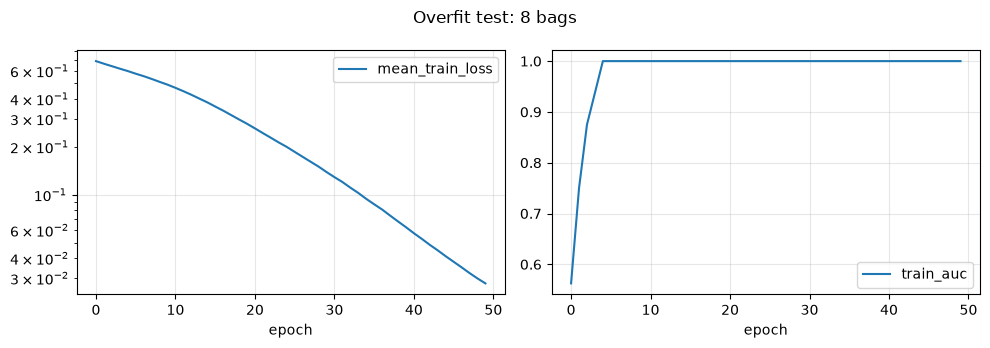

In [ ]:
plot_history(history, panels=[["mean_train_loss"], ["train_auc"]], log_panels=(0,),
             title="Overfit test: 8 bags")

In [ ]:
seed = 1337
torch.manual_seed(seed)
rng = np.random.default_rng(seed)

model = ABMIL()
model = model.to(device)

optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=0.01)

n_pos = int(train_y.sum())
n_neg = len(train_y) - n_pos
criterion = BCEWithLogitsLoss(pos_weight=torch.tensor([n_neg/n_pos], device=device))

history = []
# for each epoch, shuffle order of training bags differently
for epoch in range(n_epochs):
    model.train()
    order = rng.permutation(len(train_bags))
    for i in order:
        bag, label = train_bags[i], train_y[i]
        # Convert bags, labels to tensors
        bag_t = torch.from_numpy(bag).to(device)
        label_t = torch.tensor([float(label)], device=device)
        
        # forward pass
        logit, attn = model(bag_t)
        # calculate loss
        loss = criterion(logit, label_t)
        
        # backward pass
        # clearing gradients from previous step
        optimizer.zero_grad(set_to_none=True)
        # calculate gradients for all params
        loss.backward()
        # use gradients to update parameters to minimize loss
        optimizer.step()
    
    # Evaluate at the end of each epoch
    mean_train_loss, train_auc, _ = evaluate(model, train_bags, train_y, criterion, device)
    mean_val_loss, val_auc, _ = evaluate(model, val_bags,val_y, criterion, device)
    history.append({"epoch": epoch, "mean_train_loss": mean_train_loss, "mean_val_loss": mean_val_loss,
                    "train_auc": train_auc, "val_auc": val_auc})
    print(f"epoch {epoch}: train {mean_train_loss:.3f} / val {mean_val_loss:.3f}, val AUC {val_auc:.3f}")

epoch 0: train 0.763 / val 0.805, val AUC 0.461
epoch 1: train 0.745 / val 0.823, val AUC 0.442
epoch 2: train 0.698 / val 0.797, val AUC 0.503
epoch 3: train 0.671 / val 0.793, val AUC 0.539
epoch 4: train 0.641 / val 0.789, val AUC 0.576
epoch 5: train 0.616 / val 0.788, val AUC 0.612
epoch 6: train 0.591 / val 0.776, val AUC 0.624
epoch 7: train 0.560 / val 0.764, val AUC 0.618
epoch 8: train 0.541 / val 0.766, val AUC 0.618
epoch 9: train 0.523 / val 0.776, val AUC 0.618
epoch 10: train 0.504 / val 0.799, val AUC 0.648
epoch 11: train 0.500 / val 0.843, val AUC 0.636
epoch 12: train 0.464 / val 0.814, val AUC 0.648
epoch 13: train 0.454 / val 0.798, val AUC 0.655
epoch 14: train 0.424 / val 0.808, val AUC 0.673
epoch 15: train 0.441 / val 0.843, val AUC 0.642
epoch 16: train 0.412 / val 0.889, val AUC 0.673
epoch 17: train 0.367 / val 0.859, val AUC 0.648
epoch 18: train 0.350 / val 0.857, val AUC 0.661
epoch 19: train 0.336 / val 0.889, val AUC 0.655
epoch 20: train 0.319 / val 0.